In [1]:
import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '4'

import random
import numpy as np
import matplotlib.pyplot as plt
import copy
import math
import time
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

SEED = 42
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
       torch.cuda.manual_seed(seed)
       torch.cuda.manual_seed_all(seed)
       torch.backends.cudnn.deterministic = False
       torch.backends.cudnn.benchmark = True

set_seed(SEED)

In [2]:
!pwd

/home/jovyan/work/PyTorch/Classificacao/animals_10_kaggle/Transfer Learning/animals_10_kaggle - Resnet18


# Setup

In [3]:
PATH = "/home/jovyan/work/Datasets/animals_10_kaggle/animals_10_kaggle/raw-img"

EPOCHS = 40
PATIENCE_ES = 8

BATCH_SIZE = 64


LR = 1e-3
MIN_LR = 1e-7
GRAD_CLIP = 1.0

IMG_SIZE = (224, 224)
MODEL_SAVE_PATH = "best__resnet18.pt"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {DEVICE}")

Device: cuda


# Dataset

In [4]:
NORMALIZE_MEAN = (0.485, 0.456, 0.406)
NORMALIZE_STD = (0.229, 0.224, 0.225)

In [5]:
train_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.RandomHorizontalFlip(p=0.1),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

val_test_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

In [6]:
full_data_structure = datasets.ImageFolder(PATH)
class_names = full_data_structure.classes
total_len = len(full_data_structure)

train_len = int(0.8 * total_len)
val_len = int(0.1 * total_len)
test_len = total_len - train_len - val_len

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(total_len, generator=generator).tolist()

train_indices = indices[:train_len]
val_indices = indices[train_len : train_len + val_len]
test_indices = indices[train_len + val_len :]

train_dataset = torch.utils.data.Subset(
    datasets.ImageFolder(PATH, transform=train_transforms),
    train_indices
)

val_dataset = torch.utils.data.Subset(
    datasets.ImageFolder(PATH, transform=val_test_transforms),
    val_indices
)

test_dataset = torch.utils.data.Subset(
    datasets.ImageFolder(PATH, transform=val_test_transforms),
    test_indices
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=4, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=4, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=4, pin_memory=True, persistent_workers=True)

print(f"Classes: {len(class_names)}")
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

Classes: 10
Train: 20943 | Val: 2617 | Test: 2619


Distribuicao no treino:
  butterfly                     : 1683
  cat                           : 1329
  chicken                       : 2476
  cow                           : 1475
  dog                           : 3907
  elephant                      : 1133
  horse                         : 2123
  sheep                         : 1460
  spider                        : 3876
  squirrel                      : 1481


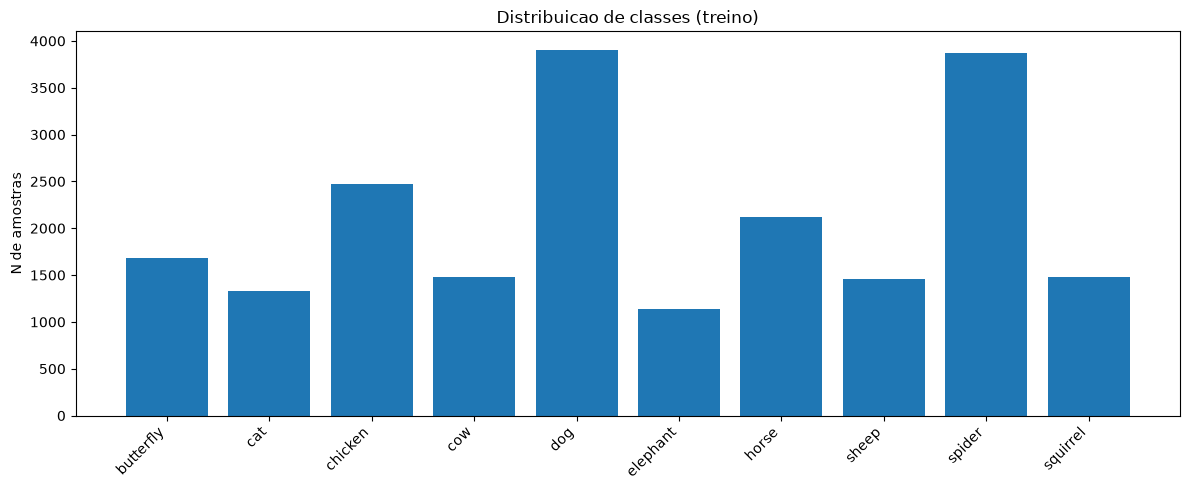

Class weights: [1.244385004043579, 1.575846552848816, 0.8458400368690491, 1.4198644161224365, 0.5360378623008728, 1.8484554290771484, 0.9864813685417175, 1.4344520568847656, 0.5403251051902771, 1.4141120910644531]


In [7]:
import numpy as np

# Conta as classes APENAS no split de treino (evita vazamento de val/test)
all_targets = np.array(full_data_structure.targets)
train_targets = all_targets[train_indices]
train_counts = np.bincount(train_targets, minlength=len(class_names))

print("Distribuicao no treino:")
for name, count in zip(class_names, train_counts):
    print(f"  {name:30s}: {count}")

plt.figure(figsize=(12, 5))
plt.bar(class_names, train_counts)
plt.xticks(rotation=45, ha='right')
plt.ylabel("N de amostras")
plt.title("Distribuicao de classes (treino)")
plt.tight_layout()
plt.show()

# Pesos inversos a frequencia (estilo sklearn 'balanced'): soma == n_classes
class_weights = len(train_targets) / (len(class_names) * train_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print(f"Class weights: {class_weights.tolist()}")

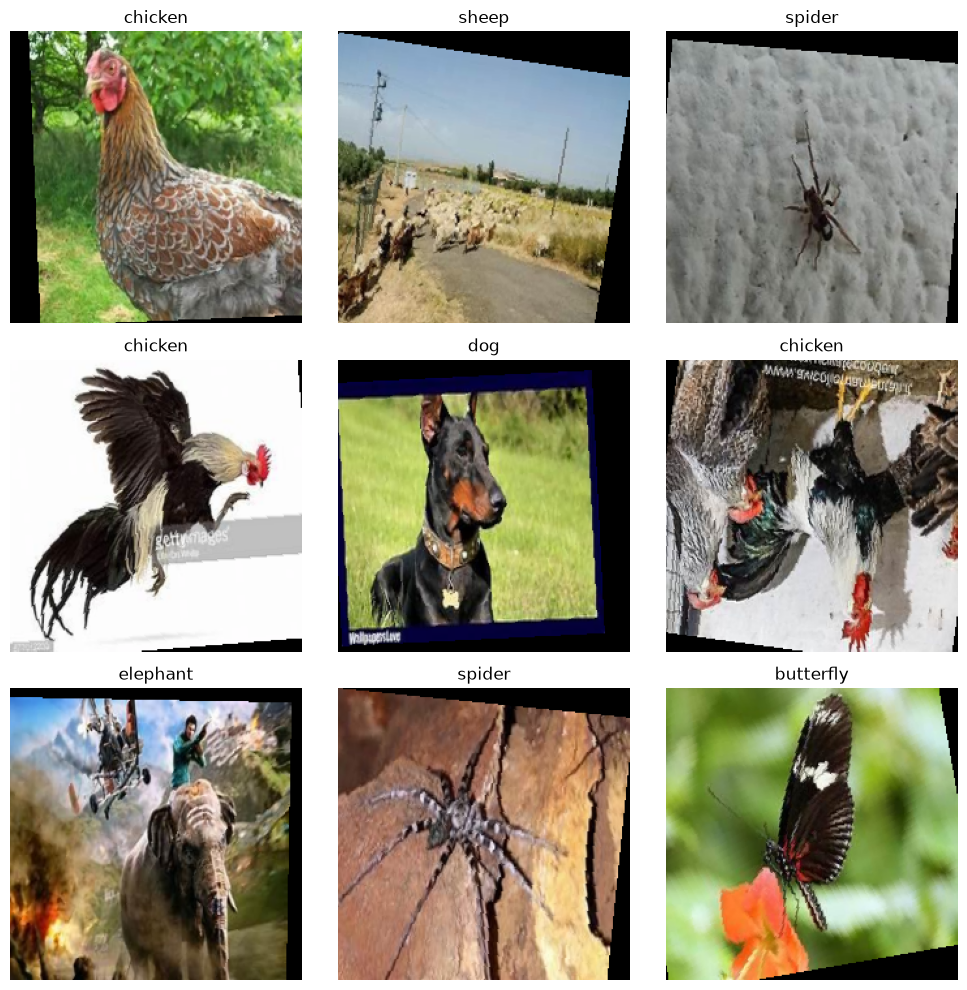

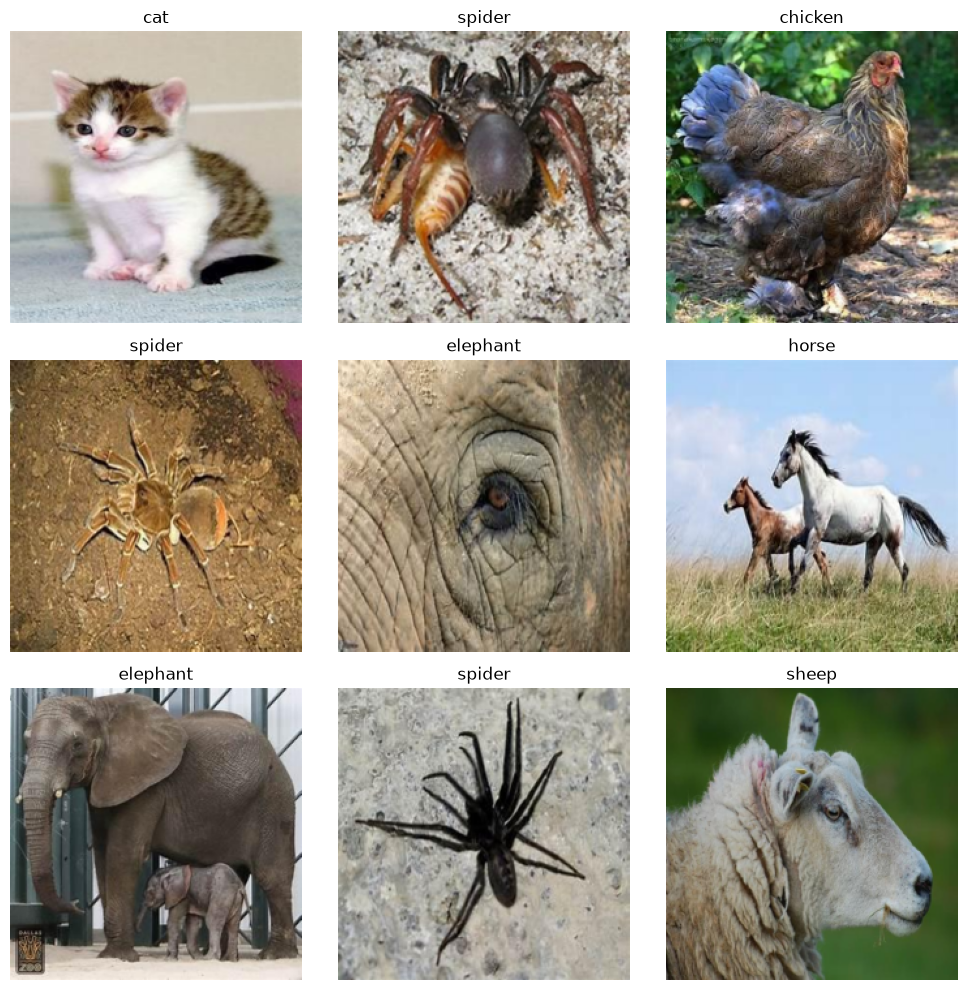

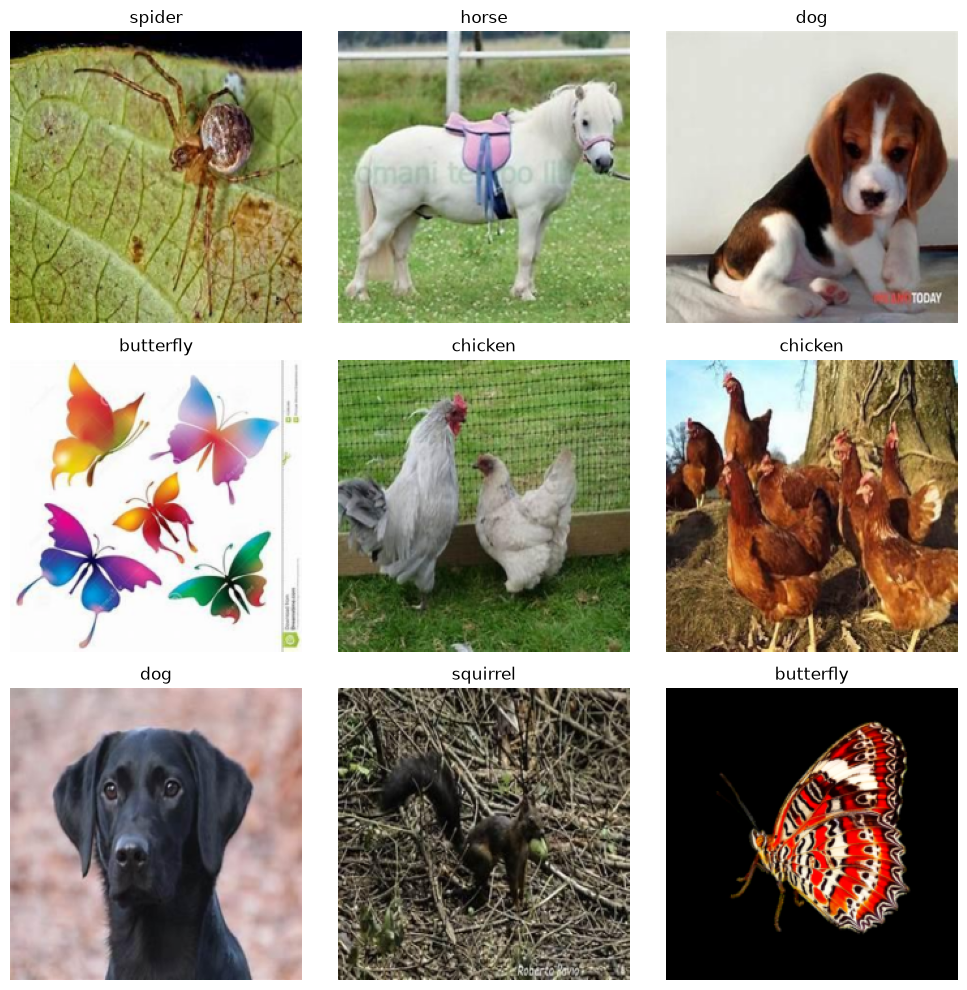

In [8]:
def plot_samples(dataset, class_names, num_samples=9):
    cols = 3
    rows = math.ceil(num_samples / cols)
    plt.figure(figsize=(10, 10))
    
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    indices = random.sample(range(len(dataset)), num_samples)
    for i, idx in enumerate(indices):
        img_tensor, label = dataset[idx]
        img_np = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        
        ax = plt.subplot(rows, cols, i + 1)
        plt.imshow(img_np)
        plt.title(class_names[label])
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

plot_samples(train_dataset, class_names)
plot_samples(test_dataset, class_names)
plot_samples(val_dataset, class_names)

# Model

In [9]:
import timm

In [10]:
model = timm.create_model(
    "resnet18",
    pretrained=True,
    num_classes=len(class_names),
    drop_rate=0.3,
).to(DEVICE)

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

In [11]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total Parameters: {total_params:,}")

Total Parameters: 11,181,642


# Train

In [12]:
# Fine-tuning: classifier novo (aleatorio) precisa de LR maior que o backbone pre-treinado
backbone_params = [p for n, p in model.named_parameters() if not n.startswith('fc')]
head_params     = [p for n, p in model.named_parameters() if n.startswith('fc')]

optimizer = optim.AdamW(
    [
        {"params": backbone_params, "lr": LR / 10},
        {"params": head_params, "lr": LR},
    ],
    weight_decay=1e-4,
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05,
)

scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[LR / 10, LR],
    steps_per_epoch=len(train_loader),
    epochs=EPOCHS,
    div_factor=100,
    final_div_factor=100,
)

# Treinamento
best_acc = 0.0
patience_counter = 0
best_model_wts = copy.deepcopy(model.state_dict())

train_losses, val_losses = [], []
train_accs, val_accs = [], []

In [13]:
from tqdm.auto import tqdm

print("Iniciando treinamento...")

for epoch in tqdm(range(EPOCHS), desc="Training Progress"):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = correct_train / total_train
    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc)

    model.eval()
    val_loss_running = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss_running += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = val_loss_running / len(val_dataset)
    val_acc = correct_val / total_val
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    tqdm.write(
        f"[{epoch+1:03d}/{EPOCHS}] "
        f"train_loss={epoch_loss:.4f} train_acc={epoch_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
        f"lr={current_lr:.2e}"
    )

    if val_acc > best_acc:
        best_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        patience_counter = 0
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE_ES:
            tqdm.write(f"Early Stopping ativado na epoch {epoch + 1}.")
            break

model.load_state_dict(best_model_wts)
print(f"Melhor Acurácia Validação: {best_acc:.4f}")

Iniciando treinamento...


Training Progress:   0%|          | 0/40 [00:00<?, ?it/s]

[001/40] train_loss=2.3208 train_acc=0.1162 | val_loss=2.2493 val_acc=0.2369 | lr=2.69e-06
[002/40] train_loss=2.1271 train_acc=0.3807 | val_loss=1.8787 val_acc=0.7459 | lr=7.64e-06
[003/40] train_loss=1.5412 train_acc=0.7579 | val_loss=0.9914 val_acc=0.8926 | lr=1.55e-05
[004/40] train_loss=0.8442 train_acc=0.8684 | val_loss=0.5652 val_acc=0.9377 | lr=2.58e-05
[005/40] train_loss=0.6350 train_acc=0.9053 | val_loss=0.5100 val_acc=0.9496 | lr=3.77e-05
[006/40] train_loss=0.5779 train_acc=0.9206 | val_loss=0.4739 val_acc=0.9576 | lr=5.05e-05
[007/40] train_loss=0.5371 train_acc=0.9351 | val_loss=0.4621 val_acc=0.9587 | lr=6.33e-05
[008/40] train_loss=0.5202 train_acc=0.9395 | val_loss=0.4532 val_acc=0.9626 | lr=7.53e-05
[009/40] train_loss=0.4960 train_acc=0.9479 | val_loss=0.4405 val_acc=0.9668 | lr=8.55e-05
[010/40] train_loss=0.4820 train_acc=0.9523 | val_loss=0.4401 val_acc=0.9656 | lr=9.34e-05
[011/40] train_loss=0.4707 train_acc=0.9565 | val_loss=0.4284 val_acc=0.9725 | lr=9.83e-05

# Test

Acurácia Final no Test Set: 0.9725


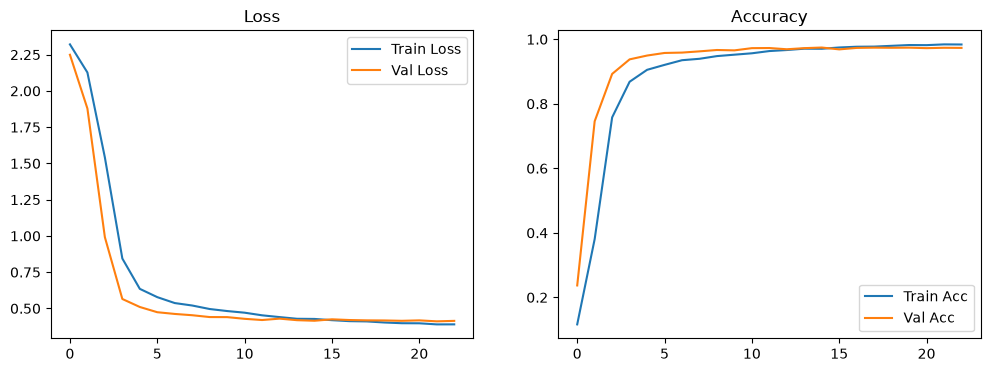

In [14]:
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

print(f"Acurácia Final no Test Set: {test_correct / test_total:.4f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.legend()
plt.title("Loss")

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.legend()
plt.title("Accuracy")
plt.show()

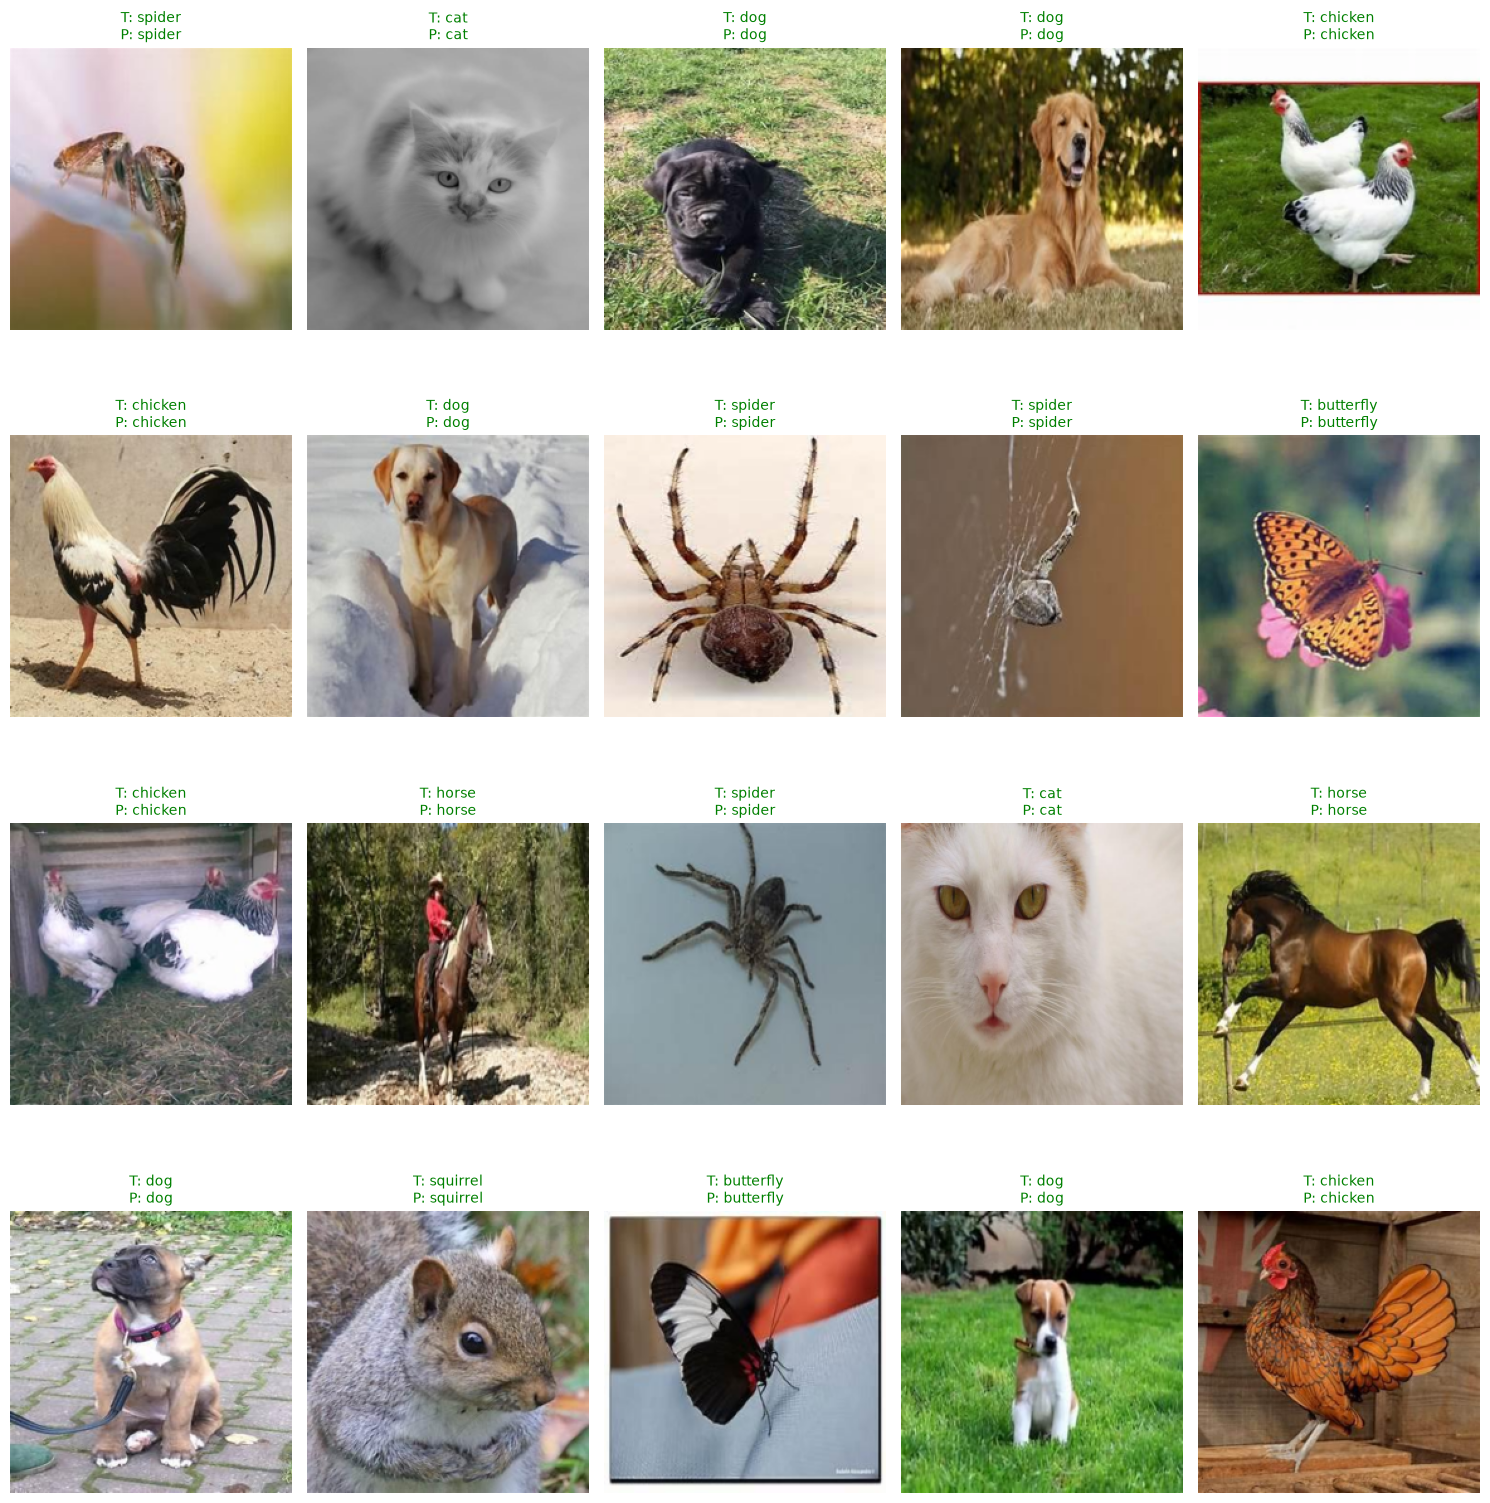

In [15]:
def predict_and_plot(model, dataset, classes, num_samples=10):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    model.eval()
    indices = random.sample(range(len(dataset)), num_samples)

    cols = 5
    rows = math.ceil(num_samples / cols)

    plt.figure(figsize=(15, 4 * rows))
    for i, idx in enumerate(indices):
        img_tensor, label = dataset[idx]
        img_input = img_tensor.unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            output = model(img_input)
            pred = output.argmax(dim=1).item()

        img_np = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img_np)

        color = 'green' if pred == label else 'red'
        plt.title(f"T: {classes[label]}\nP: {classes[pred]}", color=color, fontsize=10)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

predict_and_plot(model, test_dataset, class_names, num_samples=20)

              precision    recall  f1-score   support

   butterfly     0.9457    0.9858    0.9654       212
         cat     0.9344    0.9942    0.9634       172
     chicken     0.9820    0.9850    0.9835       333
         cow     0.9330    0.9679    0.9501       187
         dog     0.9870    0.9520    0.9692       479
    elephant     0.9752    0.9691    0.9721       162
       horse     0.9689    0.9614    0.9651       259
       sheep     0.9711    0.9655    0.9683       174
      spider     0.9956    0.9784    0.9869       462
    squirrel     0.9778    0.9832    0.9805       179

    accuracy                         0.9725      2619
   macro avg     0.9671    0.9743    0.9705      2619
weighted avg     0.9730    0.9725    0.9726      2619



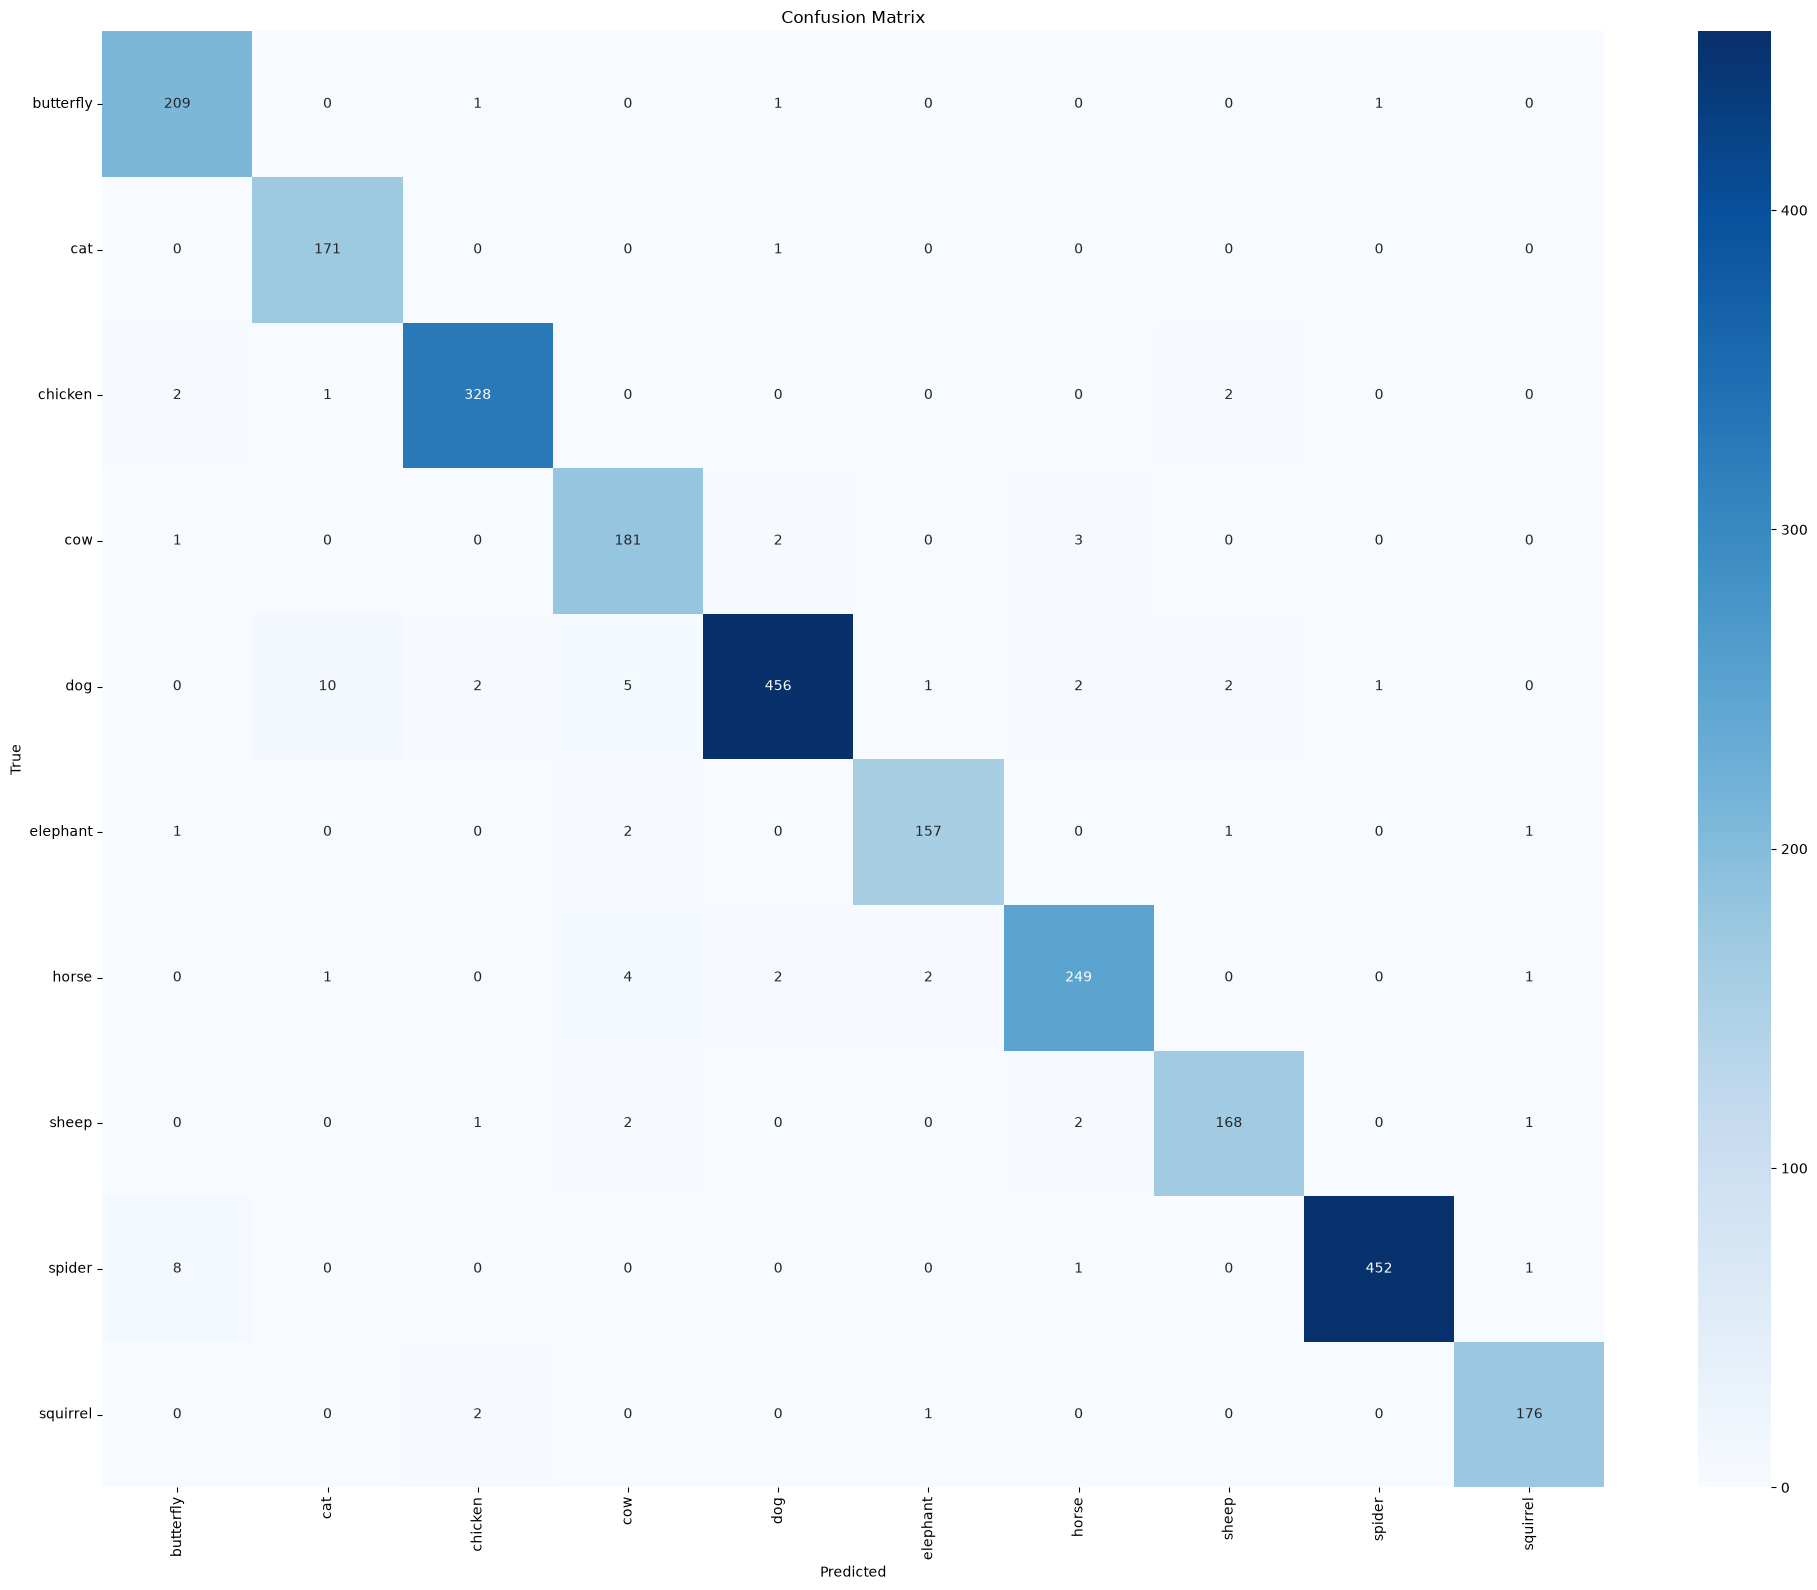

In [16]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

labels = range(len(class_names))

print(
    classification_report(
        all_labels,
        all_preds,
        labels=labels,
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)

cm = confusion_matrix(all_labels, all_preds, labels=labels)
plt.figure(figsize=(20, 16))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()